# Лабораторная работа №2

## Обучение диалоговых моделей с архитектурами Decoder-only и Encoder-decoder

**Цель работы:** исследовать качество генерации ответов диалоговыми языковыми моделями с различными архитектурами, выполнить их дообучение на диалоговом датасете и сравнить качество исходных и дообученных моделей с использованием метрик BLEU и METEOR.

**Задачи работы:**

1. Выбрать модели с архитектурами Decoder-only и Encoder-decoder.
2. Выбрать подходящий диалоговый датасет.
3. Проверить исходные модели в режиме zero-shot.
4. Рассчитать BLEU и METEOR исходных моделей.
5. Дообучить обе модели.
6. Проверить генерацию ответов после дообучения.
7. Рассчитать BLEU и METEOR дообученных моделей.
8. Сравнить результаты и сформулировать выводы.

## 1. Выбор моделей

Для выполнения лабораторной работы выбраны две предварительно обученные языковые модели с различными архитектурами.

### 1.1. Decoder-only: microsoft/DialoGPT-small

**DialoGPT-small** — авторегрессионная языковая модель, основанная на архитектуре GPT-2 и предназначенная для генерации диалоговых ответов.

Модель использует только декодер Transformer и формирует ответ последовательно, предсказывая каждый следующий токен на основе предыдущих.

Модель содержит приблизительно 117 миллионов параметров.

**Преимущества выбора:**
- Специализация на диалоговой генерации.
- Небольшой размер и относительно низкие требования к вычислительным ресурсам.
- Возможность полного дообучения на доступной видеокарте.

Ссылка: https://huggingface.co/microsoft/DialoGPT-small

### 1.2. Encoder-decoder: google/flan-t5-base

**FLAN-T5-base** — языковая модель с архитектурой Encoder-decoder, основанная на T5 и дополнительно обученная выполнять текстовые инструкции.

Энкодер модели обрабатывает входной контекст диалога, после чего декодер генерирует соответствующий ответ.

Модель содержит приблизительно 248 миллионов параметров.

**Преимущества выбора:**
- Поддержка генерации текста по входному запросу.
- Возможность использования инструкций для управления генерацией.
- Подходящая архитектура для задачи преобразования контекста диалога в ответ.

Ссылка: https://huggingface.co/google/flan-t5-base

1.3. Задаём названия моделей

Мы создаём две переменные с идентификаторами моделей на Hugging Face. Далее будем использовать эти переменные вместо повторного написания названий моделей.

In [1]:

DECODER_MODEL = "microsoft/DialoGPT-small"
ENCODER_DECODER_MODEL = "google/flan-t5-base"

print("Выбранные модели:")
print("Decoder-only:", DECODER_MODEL)
print("Encoder-decoder:", ENCODER_DECODER_MODEL)


Выбранные модели:
Decoder-only: microsoft/DialoGPT-small
Encoder-decoder: google/flan-t5-base


## 2. Выбор и подготовка датасета

### 2.1. Выбор датасета

Для обучения и оценки диалоговых моделей выбран датасет **DailyDialog**, доступный на платформе Hugging Face.

Ссылка: https://huggingface.co/datasets/OpenRL/daily_dialog

DailyDialog представляет собой корпус англоязычных диалогов на повседневные темы. Он содержит последовательности реплик участников разговора, которые могут быть использованы для обучения моделей генерации следующего ответа.

Датасет содержит три подмножества:

| Подмножество | Количество диалогов | Назначение |
|---|---:|---|
| Train | 11 118 | Обучение моделей |
| Validation | 1 000 | Оценка качества |
| Test | 1 000 | Независимое тестирование |

### 2.2. Обоснование выбора

Датасет DailyDialog подходит для поставленной задачи по следующим причинам:

- Содержит диалоги с естественными репликами собеседников.
- Позволяет формировать обучающие пары «контекст диалога → следующая реплика».
- Имеет готовое разделение на обучающую, валидационную и тестовую выборки.
- Подходит для обеих выбранных архитектур: Decoder-only и Encoder-decoder.
- Содержит относительно короткие диалоги, что снижает вычислительные затраты на обучение.

### 2.3. Способ использования

Из исходных диалогов будут сформированы пары, в которых входом является предыдущая реплика или несколько предыдущих реплик, а целевой последовательностью — следующий ответ собеседника.

Для обеих моделей будут использоваться одинаковые обучающие и валидационные примеры.

Это позволит сравнить качество генерации до и после дообучения в одинаковых условиях.

Импорт библиотек и настройка воспроизводимости

In [ ]:
# Импорт библиотек

import os
import gc
import json
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader

from tqdm.auto import tqdm

from datasets import load_dataset, Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    get_linear_schedule_with_warmup
)

import evaluate
import nltk


# Фиксация случайного зерна

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# Настройка устройства

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Используемое устройство:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Видеопамять:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "ГБ"
    )


# Параметры генерации

MAX_INPUT_LENGTH = 128
MAX_TARGET_LENGTH = 64
BATCH_SIZE_EVAL = 16


# Параметры обучения

LEARNING_RATE = 2e-5
EPOCHS = 5

BATCH_SIZE_TRAIN = 4
GRADIENT_ACCUMULATION_STEPS = 4
WEIGHT_DECAY = 0.01


# Пути сохранения моделей

DIALOGPT_SAVE_PATH = "models/dialogpt_finetuned"
FLAN_SAVE_PATH = "models/flan_t5_finetuned"


# Создание папок

for folder in ["data", "results", "models"]:
    os.makedirs(folder, exist_ok=True)


# Загрузка ресурсов NLTK

for resource in [
    "wordnet",
    "omw-1.4",
    "punkt",
    "punkt_tab"
]:
    nltk.download(resource, quiet=True)


# Вывод параметров эксперимента

print("\nПараметры обучения:")
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE_TRAIN)
print(
    "Effective batch size:",
    BATCH_SIZE_TRAIN * GRADIENT_ACCUMULATION_STEPS
)

print("\nПараметры генерации:")
print("Max input length:", MAX_INPUT_LENGTH)
print("Max target length:", MAX_TARGET_LENGTH)
print("Evaluation batch size:", BATCH_SIZE_EVAL)

print("\nОкружение успешно настроено.")


PyTorch: 2.11.0+cu128
Используемое устройство: cuda:0
GPU: NVIDIA GeForce RTX 3060
Видеопамять: 12.0 ГБ

Параметры обучения:
Epochs: 5
Learning rate: 2e-05
Batch size: 4
Effective batch size: 16

Параметры генерации:
Max input length: 128
Max target length: 64
Evaluation batch size: 16

Окружение успешно настроено.


/home/lonaogoda/spailb/.venvconvlb/lib/python3.10/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/lonaogoda/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


Конфигурация датасета

задаём параметры дальнейшего эксперимента.
Мы используем 2 000 обучающих диалогов и 200 валидационных. После преобразования в пары количество примеров будет больше, поскольку один диалог содержит несколько реплик.
Такой объём подходит для первоначального эксперимента

In [9]:
DATASET_NAME = "OpenRL/daily_dialog"

# Количество исходных диалогов
TRAIN_DIALOGS = 2000
VAL_DIALOGS = 200
TEST_DIALOGS = 200

# Количество предыдущих реплик в контексте
MAX_CONTEXT_TURNS = 3

# Максимальная длина последовательностей в токенах
MAX_INPUT_LENGTH = 128
MAX_TARGET_LENGTH = 64

print("Датасет:", DATASET_NAME)
print("Обучающих диалогов:", TRAIN_DIALOGS)
print("Валидационных диалогов:", VAL_DIALOGS)
print("Максимум реплик в контексте:", MAX_CONTEXT_TURNS)


Датасет: OpenRL/daily_dialog
Обучающих диалогов: 2000
Валидационных диалогов: 200
Максимум реплик в контексте: 3


Загрузка DailyDialog

In [4]:
dataset = load_dataset(DATASET_NAME)

print(dataset)


DatasetDict({
    train: Dataset({
        features: ['dialog', 'act', 'emotion'],
        num_rows: 11118
    })
    validation: Dataset({
        features: ['dialog', 'act', 'emotion'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['dialog', 'act', 'emotion'],
        num_rows: 1000
    })
})


Исследование структуры датасета

In [5]:
print("Структура одного примера:")
print(dataset["train"][0])

print("\nНазвания полей:")
print(dataset["train"].column_names)

print("\nКоличество диалогов:")
for split_name, split_data in dataset.items():
    print(f"{split_name}: {len(split_data)}")


Структура одного примера:
{'dialog': ['Say , Jim , how about going for a few beers after dinner ? ', ' You know that is tempting but is really not good for our fitness . ', ' What do you mean ? It will help us to relax . ', " Do you really think so ? I don't . It will just make us fat and act silly . Remember last time ? ", " I guess you are right.But what shall we do ? I don't feel like sitting at home . ", ' I suggest a walk over to the gym where we can play singsong and meet some of our friends . ', " That's a good idea . I hear Mary and Sally often go there to play pingpong.Perhaps we can make a foursome with them . ", ' Sounds great to me ! If they are willing , we could ask them to go dancing with us.That is excellent exercise and fun , too . ', " Good.Let ' s go now . ", ' All right . '], 'act': [3, 4, 2, 2, 2, 3, 4, 1, 3, 4], 'emotion': [0, 0, 0, 0, 0, 0, 4, 4, 4, 4]}

Названия полей:
['dialog', 'act', 'emotion']

Количество диалогов:
train: 11118
validation: 1000
test: 1000


Просмотр диалога

In [6]:
def get_turns(example):
    dialog = example["dialog"]

    if isinstance(dialog, str):
        dialog = json.loads(dialog)

    return [
        str(turn).strip()
        for turn in dialog
    ]


example = dataset["train"][0]
turns = get_turns(example)

print("Пример диалога DailyDialog:")
print("=" * 60)

for i, turn in enumerate(turns):
    speaker = "User" if i % 2 == 0 else "Assistant"
    print(f"{speaker}: {turn}")


Пример диалога DailyDialog:
User: Say , Jim , how about going for a few beers after dinner ?
Assistant: You know that is tempting but is really not good for our fitness .
User: What do you mean ? It will help us to relax .
Assistant: Do you really think so ? I don't . It will just make us fat and act silly . Remember last time ?
User: I guess you are right.But what shall we do ? I don't feel like sitting at home .
Assistant: I suggest a walk over to the gym where we can play singsong and meet some of our friends .
User: That's a good idea . I hear Mary and Sally often go there to play pingpong.Perhaps we can make a foursome with them .
Assistant: Sounds great to me ! If they are willing , we could ask them to go dancing with us.That is excellent exercise and fun , too .
User: Good.Let ' s go now .
Assistant: All right .


Создание обучающего и валидационного сабсетов

выбираем часть диалогов из исходных разделов датасета.
Сначала перемешиваем диалоги с фиксированным SEED, затем выбираем необходимое количество.

валидационные данные не используются для обучения. Они понадобятся нам для расчёта BLEU и METEOR до и после дообучения.

In [10]:
train_subset = (
    dataset["train"]
    .shuffle(seed=SEED)
    .select(range(TRAIN_DIALOGS))
)

val_subset = (
    dataset["validation"]
    .shuffle(seed=SEED)
    .select(range(VAL_DIALOGS))
)
test_subset = (
    dataset["test"]
    .shuffle(seed=SEED)
    .select(range(TEST_DIALOGS))
)

print("Тестовый сабсет:", len(test_subset))

print("Обучающий сабсет:", len(train_subset))
print("Валидационный сабсет:", len(val_subset))

assert len(train_subset) == TRAIN_DIALOGS
assert len(val_subset) == VAL_DIALOGS


Тестовый сабсет: 200
Обучающий сабсет: 2000
Валидационный сабсет: 200


Преобразование диалогов в пары «контекст - ответ»

In [11]:
def create_dialog_pairs(split, max_context_turns=3):
    pairs = []

    for example in split:
        turns = get_turns(example)

        # Целевые ответы: реплики условного Assistant
        for i in range(1, len(turns), 2):
            start = max(0, i - max_context_turns)

            context_lines = []

            for j in range(start, i):
                speaker = (
                    "User" if j % 2 == 0
                    else "Assistant"
                )

                context_lines.append(
                    f"{speaker}: {turns[j]}"
                )

            context = "\n".join(context_lines)
            response = turns[i]

            if context.strip() and response.strip():
                pairs.append({
                    "context": context,
                    "response": response
                })

    return Dataset.from_list(pairs)


train_pairs = create_dialog_pairs(
    train_subset,
    max_context_turns=MAX_CONTEXT_TURNS
)

val_pairs = create_dialog_pairs(
    val_subset,
    max_context_turns=MAX_CONTEXT_TURNS
)
test_pairs = create_dialog_pairs(
    test_subset,
    max_context_turns=MAX_CONTEXT_TURNS
)

print("Тестовых пар:", len(test_pairs))

print("Обучающих пар:", len(train_pairs))
print("Валидационных пар:", len(val_pairs))


Тестовых пар: 687
Обучающих пар: 7605
Валидационных пар: 798


Просмотр подготовленных обучающих данных

In [12]:
train_df = pd.DataFrame(train_pairs)

print("Размер таблицы:", train_df.shape)

display(train_df.head(10))


Размер таблицы: (7605, 2)


,context,response
0,User: finally we're on board !,yes . It was so crowded . I'm worn-out . Let's...
1,User: finally we're on board !\nAssistant: yes...,"let me see ... yes , one window seat and one a..."
2,User: are they window seats or aisle seats ?\n...,that's fine . I'd like to be on the aisle anyw...
3,User: ok . But can I trade my seat with you ? ...,I think the smaller carry-on bag can go in the...
4,User: thanks . Where shall we put our luggage ...,don't forget to keep the seat belt on .
5,User: good idea .\nAssistant: don't forget to ...,yes !
6,User: ok . Hope it's a pleasant trip .\nAssist...,"oh , you have too wild of an imagination ."
7,"User: Mary , why don't you come to my house th...",I don't know . I'll have to ask my host mom .
8,"User: Mary , why don't you come to my house th...",But I still have to tell her .
9,"User: Come on , Mary . This is America . You m...","Tell you what , give me your phone number ."


Сохранение подготовленных выборок

In [ ]:
# Создаём тестовые пары
test_pairs = create_dialog_pairs(
    test_subset,
    max_context_turns=MAX_CONTEXT_TURNS
)

# Сохраняем обучающую выборку
train_pairs.to_json(
    "data/train_pairs.jsonl",
    force_ascii=False
)

# Сохраняем валидационную выборку
val_pairs.to_json(
    "data/val_pairs.jsonl",
    force_ascii=False
)

# Сохраняем тестовую выборку
test_pairs.to_json(
    "data/test_pairs.jsonl",
    force_ascii=False
)

# Проверяем результаты
print("\nВсе выборки успешно сохранены!")
print("=" * 50)

print(f"Train:      {len(train_pairs)} пар -> data/train_pairs.jsonl")
print(f"Validation: {len(val_pairs)} пар -> data/val_pairs.jsonl")
print(f"Test:       {len(test_pairs)} пар -> data/test_pairs.jsonl")


Creating json from Arrow format: 100%|██████████| 1/1 [00:00<00:00, 550.58ba/s]


Все выборки успешно сохранены!
Train:      7605 пар -> data/train_pairs.jsonl
Validation: 798 пар -> data/val_pairs.jsonl
Test:       687 пар -> data/test_pairs.jsonl


## 3. Проверка исходных моделей в режиме Zero-shot

На данном этапе проводится проверка способности предварительно обученных языковых моделей генерировать ответы на запросы пользователя без дополнительного обучения на выбранном датасете.

Для эксперимента используются две модели:

- **DialoGPT-small** — модель с архитектурой Decoder-only.
- **FLAN-T5-base** — модель с архитектурой Encoder-decoder.

В качестве тестового сценария используются короткие англоязычные диалоги на повседневные темы, соответствующие тематике датасета DailyDialog.

Для каждой модели формируется входной запрос, после чего генерируется ответ. Полученные ответы анализируются с точки зрения связности, осмысленности и соответствия контексту.

На данном этапе веса моделей не изменяются.

Для обеспечения воспроизводимости используется детерминированная генерация без случайного сэмплирования (`do_sample=False`). Результаты сохраняются для дальнейшего сравнения с ответами моделей после дообучения.

Подготовка окружения для генерации

In [16]:
import os
import gc
import torch
import pandas as pd

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM
)

# Используем GPU, если она доступна
device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

# Параметры генерации
MAX_INPUT_LENGTH = 128
MAX_TARGET_LENGTH = 64

os.makedirs("results", exist_ok=True)

print("Устройство:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Видеопамять:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "ГБ"
    )


Устройство: cuda:0
GPU: NVIDIA GeForce RTX 3060
Видеопамять: 12.0 ГБ


Подготовка тестовых диалогов

Для zero-shot проверки используем пять заранее подготовленных повседневных ситуаций. Это позволит оценить модели на примерах, не взятых непосредственно из обучающей выборки.

создаём пять входных запросов для качественной проверки обеих моделей. Выбор бытовых тем соответствует характеру DailyDialog.

In [17]:
test_contexts = [
    "User: Hello! How are you today?",
    "User: What are you doing this weekend?",
    "User: I am feeling a little tired today.",
    "User: Do you like watching movies?",
    "User: Can you help me with my homework?"
]

print("Количество тестовых запросов:", len(test_contexts))

for i, context in enumerate(test_contexts, start=1):
    print(f"{i}. {context}")


Количество тестовых запросов: 5
1. User: Hello! How are you today?
2. User: What are you doing this weekend?
3. User: I am feeling a little tired today.
4. User: Do you like watching movies?
5. User: Can you help me with my homework?


Zero-shot проверка Decoder-only модели DialoGPT-small

Загрузка исходной DialoGPT-small

In [18]:
# Освобождаем память от других моделей
if "flan_model" in globals():
    del flan_model

if "dialogpt_model" in globals():
    del dialogpt_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Загружаем токенизатор
dialogpt_tokenizer = AutoTokenizer.from_pretrained(
    DECODER_MODEL
)

dialogpt_tokenizer.pad_token = (
    dialogpt_tokenizer.eos_token
)

dialogpt_tokenizer.padding_side = "left"

# Загружаем ИСХОДНУЮ модель, не обученную на DailyDialog
dialogpt_model = AutoModelForCausalLM.from_pretrained(
    DECODER_MODEL,
    dtype=torch.float32
).to(device)

dialogpt_model.config.pad_token_id = (
    dialogpt_tokenizer.pad_token_id
)

dialogpt_model.eval()

print("Модель:", DECODER_MODEL)
print("Устройство:", next(dialogpt_model.parameters()).device)
print("Тип параметров:", next(dialogpt_model.parameters()).dtype)


Loading weights: 100%|██████████| 149/149 [00:00<00:00, 653.32it/s]


Модель: microsoft/DialoGPT-small
Устройство: cuda:0
Тип параметров: torch.float32


Функция подготовки контекста для DialoGPT

DialoGPT использует специальные токены окончания реплики. Поэтому важно подготовить вход в формате, соответствующем модели.

Удаляем условные метки участников (User:, Assistant:), а реплики разделяем токеном <|endoftext|>.

In [19]:
def format_dialogpt_context(context):
    turns = []

    for line in context.split("\n"):
        if ": " in line:
            text = line.split(": ", 1)[1]
        else:
            text = line

        turns.append(text.strip())

    eos = dialogpt_tokenizer.eos_token

    return eos.join(turns) + eos


# Проверяем работу функции
example_context = test_contexts[0]

formatted = format_dialogpt_context(example_context)

print("Исходный контекст:")
print(example_context)

print("\nКонтекст для DialoGPT:")
print(repr(formatted))


Исходный контекст:
User: Hello! How are you today?

Контекст для DialoGPT:
'Hello! How are you today?<|endoftext|>'


Функция генерации ответа DialoGPT

* torch.inference_mode() отключает вычисление градиентов.
* do_sample=False задаёт детерминированную генерацию.
* max_new_tokens=64 ограничивает длину ответа.
* generated_ids содержит только токены, созданные моделью, без входного запроса.

In [20]:
@torch.inference_mode()
def generate_dialogpt(context):
    prompt = format_dialogpt_context(context)

    inputs = dialogpt_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    ).to(device)

    outputs = dialogpt_model.generate(
        **inputs,
        max_new_tokens=MAX_TARGET_LENGTH,
        do_sample=False,
        pad_token_id=dialogpt_tokenizer.pad_token_id,
        eos_token_id=dialogpt_tokenizer.eos_token_id
    )

    # Decoder-only возвращает вход + продолжение.
    # Убираем входную часть, оставляя только ответ.
    input_length = inputs["input_ids"].shape[1]

    generated_ids = outputs[0, input_length:]

    response = dialogpt_tokenizer.decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )

    return response.strip()


Zero-shot генерация DialoGPT-small

In [21]:
dialogpt_examples_before = []

print("ZERO-SHOT: DialoGPT-small")
print("=" * 60)

for i, context in enumerate(test_contexts, start=1):
    response = generate_dialogpt(context)

    dialogpt_examples_before.append(response)

    print(f"\nПример {i}")
    print("Запрос:", context)
    print("Ответ:", response)
    print("-" * 60)

assert len(dialogpt_examples_before) == len(test_contexts)


ZERO-SHOT: DialoGPT-small


[transformers] We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.
You may ignore this warning if your `pad_token_id` (50256) is identical to the `bos_token_id` (50256), `eos_token_id` (50256), or the `sep_token_id` (None), and your input is not padded.



Пример 1
Запрос: User: Hello! How are you today?
Ответ: Hi !
------------------------------------------------------------

Пример 2
Запрос: User: What are you doing this weekend?
Ответ: I'm going to the game tonight .
------------------------------------------------------------

Пример 3
Запрос: User: I am feeling a little tired today.
Ответ: I'm feeling a little tired right now .
------------------------------------------------------------

Пример 4
Запрос: User: Do you like watching movies?
Ответ: I love movies .
------------------------------------------------------------

Пример 5
Запрос: User: Can you help me with my homework?
Ответ: I can help you with your homework
------------------------------------------------------------


Zero-shot проверка Encoder-decoder модели FLAN-T5-base

Теперь проведём аналогичный эксперимент для модели с архитектурой Encoder-decoder.
В отличие от DialoGPT, FLAN-T5 умеет обрабатывать текстовые инструкции. Поэтому передадим ей контекст диалога вместе с указанием сгенерировать следующую реплику.

In [23]:
# Загружаем токенизатор
flan_tokenizer = AutoTokenizer.from_pretrained(
    ENCODER_DECODER_MODEL
)

# Загружаем исходную модель
flan_model = AutoModelForSeq2SeqLM.from_pretrained(
    ENCODER_DECODER_MODEL,
    dtype=torch.float32
).to(device)

# Режим оценки
flan_model.eval()

print("Модель:", ENCODER_DECODER_MODEL)
print("Устройство:", next(flan_model.parameters()).device)
print("Тип параметров:", next(flan_model.parameters()).dtype)


Loading weights: 100%|██████████| 282/282 [00:00<00:00, 301.81it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Модель: google/flan-t5-base
Устройство: cuda:0
Тип параметров: torch.float32


Функция подготовки контекста FLAN-T5

In [24]:
def format_flan_context(context):
    instruction = (
        "Generate a natural and relevant next reply "
        "in the following conversation. "
        "Return only the reply."
    )

    return (
        f"{instruction}\n\n"
        f"{context}\n"
        "Assistant:"
    )


example_context = test_contexts[0]

print("Исходный запрос:")
print(example_context)

print("\nВход для FLAN-T5:")
print(format_flan_context(example_context))


Исходный запрос:
User: Hello! How are you today?

Вход для FLAN-T5:
Generate a natural and relevant next reply in the following conversation. Return only the reply.

User: Hello! How are you today?
Assistant:


Функция генерации FLAN-T5

In [25]:
@torch.inference_mode()
def generate_flan(context):
    prompt = format_flan_context(context)

    inputs = flan_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    ).to(device)

    outputs = flan_model.generate(
        **inputs,
        max_new_tokens=MAX_TARGET_LENGTH,
        do_sample=False
    )

    response = flan_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )

    return response.strip()


Zero-shot генерация FLAN-T5-base

In [26]:
flan_examples_before = []

print("ZERO-SHOT: FLAN-T5-base")
print("=" * 60)

for i, context in enumerate(test_contexts, start=1):
    response = generate_flan(context)

    flan_examples_before.append(response)

    print(f"\nПример {i}")
    print("Запрос:", context)
    print("Ответ:", response)
    print("-" * 60)

assert len(flan_examples_before) == len(test_contexts)


ZERO-SHOT: FLAN-T5-base

Пример 1
Запрос: User: Hello! How are you today?
Ответ: I'm fine.
------------------------------------------------------------

Пример 2
Запрос: User: What are you doing this weekend?
Ответ: I'm going to the beach.
------------------------------------------------------------

Пример 3
Запрос: User: I am feeling a little tired today.
Ответ: I'm not sure what to do.
------------------------------------------------------------

Пример 4
Запрос: User: Do you like watching movies?
Ответ: I like to watch a lot of movies.
------------------------------------------------------------

Пример 5
Запрос: User: Can you help me with my homework?
Ответ: Sure. I'll help you with that.
------------------------------------------------------------


#### Сравнение zero-shot ответов

Таблица результатов

In [27]:
zero_shot_df = pd.DataFrame({
    "context": test_contexts,
    "dialogpt_before": dialogpt_examples_before,
    "flan_before": flan_examples_before
})

display(zero_shot_df)


,context,dialogpt_before,flan_before
0,User: Hello! How are you today?,Hi !,I'm fine.
1,User: What are you doing this weekend?,I'm going to the game tonight .,I'm going to the beach.
2,User: I am feeling a little tired today.,I'm feeling a little tired right now .,I'm not sure what to do.
3,User: Do you like watching movies?,I love movies .,I like to watch a lot of movies.
4,User: Can you help me with my homework?,I can help you with your homework,Sure. I'll help you with that.


Сохранение результатов

In [ ]:
ZERO_SHOT_PATH = "results/zero_shot_examples.csv"

zero_shot_df.to_csv(
    ZERO_SHOT_PATH,
    index=False,
    encoding="utf-8"
)

assert os.path.exists(ZERO_SHOT_PATH)

print("Результаты сохранены:", ZERO_SHOT_PATH)
print("Количество примеров:", len(zero_shot_df))


Результаты сохранены: results/zero_shot_examples.csv
Количество примеров: 5


#### Вывод по пункту 3

В ходе проверки моделей в режиме zero-shot установлено, что обе модели способны генерировать осмысленные ответы на запросы пользователя без дополнительного дообучения.

Модель **DialoGPT-small** преимущественно формирует короткие и простые ответы, которые в большинстве случаев соответствуют контексту диалога. Модель **FLAN-T5-base** чаще генерирует более развёрнутые и естественные ответы, однако некоторые из них не полностью соответствуют смыслу запроса.

Таким образом, обе модели продемонстрировали способность поддерживать повседневный диалог. На рассмотренных примерах FLAN-T5-base показала несколько более естественную генерацию, однако для объективного сравнения качества моделей необходимо дополнительно рассчитать метрики BLEU и METEOR на валидационном подмножестве датасета DailyDialog.

## 4. Расчёт метрик BLEU и METEOR исходных моделей

На данном этапе проводится количественная оценка качества генерации ответов исходных моделей DialoGPT-small и FLAN-T5-base без дополнительного дообучения.

Оценка выполняется на валидационном подмножестве датасета DailyDialog, которое не используется для обучения моделей.

Для каждого примера валидационной выборки модель получает контекст диалога и генерирует следующую реплику. Полученный ответ сравнивается с эталонной репликой из датасета.

Для оценки используются две метрики:

- **BLEU (Bilingual Evaluation Understudy)** — оценивает совпадение последовательностей слов (n-грамм) между сгенерированными и эталонными ответами.
- **METEOR (Metric for Evaluation of Translation with Explicit ORdering)** — учитывает совпадения слов, их нормализованных форм и некоторые синонимические соответствия с учётом порядка слов.

Значения метрик находятся в диапазоне от 0 до 1, где более высокое значение обычно указывает на большее соответствие эталонным ответам.

Загрузка метрик BLEU и METEOR

In [29]:
import evaluate
import nltk

nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

bleu_metric = evaluate.load("bleu")
meteor_metric = evaluate.load("meteor")

print("Метрики BLEU и METEOR успешно загружены.")


/home/lonaogoda/spailb/.venvconvlb/lib/python3.10/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/lonaogoda/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


Метрики BLEU и METEOR успешно загружены.


[nltk_data] Downloading package wordnet to
[nltk_data]     /home/lonaogoda/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/lonaogoda/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /home/lonaogoda/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Функция расчёта метрик

функция принимает два списка: predictions с ответами модели и references с эталонными ответами. Затем рассчитывает корпусный BLEU и METEOR.

In [30]:
def calculate_metrics(predictions, references):
    predictions = list(predictions)
    references = list(references)

    if not predictions:
        raise ValueError(
            "Список предсказаний пуст. "
            "Сначала необходимо выполнить генерацию."
        )

    if len(predictions) != len(references):
        raise ValueError(
            f"Количество предсказаний: {len(predictions)}, "
            f"эталонов: {len(references)}"
        )

    if not all(isinstance(x, str) for x in predictions):
        raise TypeError("Предсказания должны быть строками.")

    if not all(isinstance(x, str) for x in references):
        raise TypeError("Эталонные ответы должны быть строками.")

    if any(not x.strip() for x in references):
        raise ValueError("Обнаружены пустые эталонные ответы.")

    bleu = bleu_metric.compute(
        predictions=predictions,
        references=[[ref] for ref in references]
    )["bleu"]

    meteor = meteor_metric.compute(
        predictions=predictions,
        references=references
    )["meteor"]

    return {
        "BLEU": round(bleu, 4),
        "METEOR": round(meteor, 4)
    }


print("Функция calculate_metrics() определена.")


Функция calculate_metrics() определена.


Подготовка валидационного сабсета

формируем два списка с одинаковым порядком элементов.

In [31]:
validation_contexts = list(val_pairs["context"])
validation_references = list(val_pairs["response"])

assert len(validation_contexts) > 0
assert len(validation_contexts) == len(validation_references)

print("Количество валидационных примеров:",
      len(validation_contexts))

print("\nПервый контекст:")
print(validation_contexts[0])

print("\nЭталонный ответ:")
print(validation_references[0])


Количество валидационных примеров: 798

Первый контекст:
User: my mp3 player is broken , so I want to change it for an mp4 player . Can you offer any advice about which brand and model to buy ?

Эталонный ответ:
an mp4 player ? why don't you buy a new cell phone ? You can find an mp4 player inside any of the latest cell phones .


Расчёт метрик исходной DialoGPT-small

In [33]:
@torch.inference_mode()
def generate_dialogpt_batch(contexts):
    # Форматируем все контексты
    prompts = [
        format_dialogpt_context(context)
        for context in contexts
    ]

    # Токенизация с левым дополнением
    inputs = dialogpt_tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    ).to(device)

    # Генерация ответов
    outputs = dialogpt_model.generate(
        **inputs,
        max_new_tokens=MAX_TARGET_LENGTH,
        do_sample=False,
        pad_token_id=dialogpt_tokenizer.pad_token_id,
        eos_token_id=dialogpt_tokenizer.eos_token_id
    )

    # Удаляем токены входного контекста
    input_length = inputs["input_ids"].shape[1]
    generated_ids = outputs[:, input_length:]

    # Декодируем сгенерированные ответы
    responses = dialogpt_tokenizer.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )

    return [response.strip() for response in responses]


Загрузка исходной DialoGPT-small

In [34]:
if "flan_model" in globals():
    del flan_model

if "dialogpt_model" in globals():
    del dialogpt_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Загружаем исходную DialoGPT
dialogpt_tokenizer = AutoTokenizer.from_pretrained(
    DECODER_MODEL
)

dialogpt_tokenizer.pad_token = (
    dialogpt_tokenizer.eos_token
)

dialogpt_tokenizer.padding_side = "left"

dialogpt_model = AutoModelForCausalLM.from_pretrained(
    DECODER_MODEL,
    dtype=torch.float32
).to(device)

dialogpt_model.config.pad_token_id = (
    dialogpt_tokenizer.pad_token_id
)

dialogpt_model.eval()

print("Загружена исходная модель:", DECODER_MODEL)
print("Устройство:", next(dialogpt_model.parameters()).device)


Loading weights: 100%|██████████| 149/149 [00:00<00:00, 665.20it/s]


Загружена исходная модель: microsoft/DialoGPT-small
Устройство: cuda:0


Проверка пакетной генерации на нескольких примерах

In [35]:
sample_contexts = validation_contexts[:4]

sample_predictions = generate_dialogpt_batch(
    sample_contexts
)

for i, (context, prediction, reference) in enumerate(
    zip(
        sample_contexts,
        sample_predictions,
        validation_references[:4]
    ),
    start=1
):
    print(f"\nПример {i}")
    print("Контекст:", context)
    print("Эталон:", reference)
    print("Предсказание:", prediction)
    print("-" * 60)

assert len(sample_predictions) == 4

print("\nПакетная генерация DialoGPT работает.")



Пример 1
Контекст: User: my mp3 player is broken , so I want to change it for an mp4 player . Can you offer any advice about which brand and model to buy ?
Эталон: an mp4 player ? why don't you buy a new cell phone ? You can find an mp4 player inside any of the latest cell phones .
Предсказание: I have a mp3 player that I use for my phone . I use it for music and video .
------------------------------------------------------------

Пример 2
Контекст: User: my mp3 player is broken , so I want to change it for an mp4 player . Can you offer any advice about which brand and model to buy ?
Assistant: an mp4 player ? why don't you buy a new cell phone ? You can find an mp4 player inside any of the latest cell phones .
User: Oh , that's a good idea . Perhaps I should have a try .
Эталон: look at my cell phone . I can listen to music , watch movies , take pictures , play games , surf the web and download documents . It's just like a PAD .
Предсказание: I would recommend a cell phone .
-------

Генерация ответов DialoGPT на валидационном сабсете

модель генерирует ответ для каждого из валидационных контекстов. Результаты сохраняются в dialogpt_predictions_before.

In [36]:
dialogpt_predictions_before = []

for i in tqdm(
    range(
        0,
        len(validation_contexts),
        BATCH_SIZE_EVAL
    ),
    desc="DialoGPT baseline"
):
    batch = validation_contexts[
        i:i + BATCH_SIZE_EVAL
    ]

    responses = generate_dialogpt_batch(batch)

    dialogpt_predictions_before.extend(responses)

# Проверка результата
assert len(dialogpt_predictions_before) == len(
    validation_references
), "Количество ответов не совпадает с количеством эталонов"

print("Сгенерировано ответов:",
      len(dialogpt_predictions_before))

print("Пустых ответов:",
      sum(not x.strip() for x in dialogpt_predictions_before))

DialoGPT baseline: 100%|██████████| 50/50 [00:15<00:00,  3.32it/s]

Сгенерировано ответов: 798
Пустых ответов: 4


Вычисление BLEU и METEOR DialoGPT и сохранение результатов DialoGPT

In [ ]:
dialogpt_metrics_before = calculate_metrics(
    dialogpt_predictions_before,
    validation_references
)

print("DialoGPT-small: метрики до обучения")
print("=" * 45)

print("BLEU:", dialogpt_metrics_before["BLEU"])
print("METEOR:", dialogpt_metrics_before["METEOR"])

dialogpt_results_df = pd.DataFrame({
    "context": validation_contexts,
    "reference": validation_references,
    "prediction": dialogpt_predictions_before
})

dialogpt_results_df.to_csv(
    "results/dialogpt_predictions_before.csv",
    index=False,
    encoding="utf-8"
)

with open(
    "results/dialogpt_metrics_before.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        dialogpt_metrics_before,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Результаты DialoGPT сохранены.")



DialoGPT-small: метрики до обучения
BLEU: 0.0056
METEOR: 0.1049
Результаты DialoGPT сохранены.


Расчёт метрик исходной FLAN-T5-base

Освобождение видеопамяти и загрузка FLAN-T5

In [39]:
# Освобождаем память DialoGPT
if "dialogpt_model" in globals():
    del dialogpt_model

if "flan_model" in globals():
    del flan_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Загружаем исходную FLAN-T5
flan_tokenizer = AutoTokenizer.from_pretrained(
    ENCODER_DECODER_MODEL
)

flan_model = AutoModelForSeq2SeqLM.from_pretrained(
    ENCODER_DECODER_MODEL,
    dtype=torch.float32
).to(device)

flan_model.eval()

print("Загружена исходная модель:", ENCODER_DECODER_MODEL)
print("Устройство:", next(flan_model.parameters()).device)
print("Тип параметров:", next(flan_model.parameters()).dtype)


Loading weights: 100%|██████████| 282/282 [00:00<00:00, 1795.14it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Загружена исходная модель: google/flan-t5-base
Устройство: cuda:0
Тип параметров: torch.float32


Функция пакетной генерации FLAN-T5

функция принимает сразу несколько контекстов и генерирует соответствующие ответы.


In [40]:
@torch.inference_mode()
def generate_flan_batch(contexts):
    # Используем тот же формат,
    # что и при zero-shot проверке
    prompts = [
        format_flan_context(context)
        for context in contexts
    ]

    # Токенизация пакета
    inputs = flan_tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    ).to(device)

    # Генерация ответов
    outputs = flan_model.generate(
        **inputs,
        max_new_tokens=MAX_TARGET_LENGTH,
        do_sample=False
    )

    # Декодирование
    responses = flan_tokenizer.batch_decode(
        outputs,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )

    return [response.strip() for response in responses]


Генерация ответов FLAN-T5 на валидационном сабсете

In [42]:
flan_predictions_before = []

for i in tqdm(
    range(
        0,
        len(validation_contexts),
        BATCH_SIZE_EVAL
    ),
    desc="FLAN-T5 baseline"
):
    batch = validation_contexts[
        i:i + BATCH_SIZE_EVAL
    ]

    responses = generate_flan_batch(batch)

    flan_predictions_before.extend(responses)

# Проверяем количество ответов
assert len(flan_predictions_before) == len(
    validation_references
), "Количество ответов не совпадает с количеством эталонов"

print("Сгенерировано ответов:",
      len(flan_predictions_before))

print("Пустых ответов:",
      sum(not x.strip() for x in flan_predictions_before))


FLAN-T5 baseline: 100%|██████████| 50/50 [00:19<00:00,  2.53it/s]

Сгенерировано ответов: 798
Пустых ответов: 0


Вычисление BLEU и METEOR FLAN-T5 и сохранение результатов FLAN-T5

In [43]:
flan_metrics_before = calculate_metrics(
    flan_predictions_before,
    validation_references
)

print("FLAN-T5-base: метрики до обучения")
print("=" * 45)

print("BLEU:", flan_metrics_before["BLEU"])
print("METEOR:", flan_metrics_before["METEOR"])


flan_results_df = pd.DataFrame({
    "context": validation_contexts,
    "reference": validation_references,
    "prediction": flan_predictions_before
})

flan_results_df.to_csv(
    "results/flan_predictions_before.csv",
    index=False,
    encoding="utf-8"
)

with open(
    "results/flan_metrics_before.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        flan_metrics_before,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Результаты FLAN-T5 сохранены.")



FLAN-T5-base: метрики до обучения
BLEU: 0.0104
METEOR: 0.1213
Результаты FLAN-T5 сохранены.


Сравнение исходных моделей

In [44]:
metrics_before_df = pd.DataFrame([
    {
        "Модель": "DialoGPT-small",
        "Архитектура": "Decoder-only",
        "BLEU": dialogpt_metrics_before["BLEU"],
        "METEOR": dialogpt_metrics_before["METEOR"]
    },
    {
        "Модель": "FLAN-T5-base",
        "Архитектура": "Encoder-decoder",
        "BLEU": flan_metrics_before["BLEU"],
        "METEOR": flan_metrics_before["METEOR"]
    }
])

display(metrics_before_df)

metrics_before_df.to_csv(
    "results/metrics_before.csv",
    index=False,
    encoding="utf-8"
)


,Модель,Архитектура,BLEU,METEOR
0,DialoGPT-small,Decoder-only,0.0056,0.1049
1,FLAN-T5-base,Encoder-decoder,0.0104,0.1213


Сравнение сгенерированных ответов

In [45]:
predictions_before_df = pd.DataFrame({
    "context": validation_contexts,
    "reference": validation_references,
    "dialogpt_before": dialogpt_predictions_before,
    "flan_before": flan_predictions_before
})

display(predictions_before_df.head(10))

predictions_before_df.to_csv(
    "results/predictions_before.csv",
    index=False,
    encoding="utf-8"
)


,context,reference,dialogpt_before,flan_before
0,"User: my mp3 player is broken , so I want to c...",an mp4 player ? why don't you buy a new cell p...,I have a mp3 player that I use for my phone . ...,I am not sure .
1,"User: my mp3 player is broken , so I want to c...",look at my cell phone . I can listen to music ...,I would recommend a cell phone .,I will try .
2,"User: Oh , that's a good idea . Perhaps I shou...","that's Ok . you know , digital devices are bec...",I'm a computer guy . I can do it .,The assistant may be a little too slow .
3,User: that's cool . I can use the computer and...,that's right . what's the flash memory of your...,"I'm not sure if you're joking or not , but you...",I can listen to music on my phone .
4,"User: yeah , if I buy a cell phone like this ,...",then any cell phone can meet your need because...,how big is your storage ?,That's right .
5,User: What is the annual salary for this job ?,The annual salary is sixty-five thousand dolla...,I'm a software engineer .,"The salary is $ 59,500."
6,User: What is the annual salary for this job ?...,"This job pays for half of your medical , denta...",I'm not sure what you mean .,"The benefits package includes a 401 k , a comp..."
7,User: What does the benefits package include ?...,You have a total of 21 days paid time off whic...,I'm in the same boat . I'm in the same boat .,This job pays for a year .
8,User: Do we get paid time off ?\nAssistant: Yo...,We still offer a traditional retirement plan t...,I'm not sure what you mean by that .,You have a total of 62 days of paid time off .
9,User: How about retirement ?\nAssistant: We st...,We offer full tuition reimbursement for job re...,You can get a job at a company that pays you a...,We offer a specialized training program .


### Вывод по пункту 4

В ходе оценки исходных моделей на валидационном подмножестве датасета DailyDialog были получены значения метрик BLEU и METEOR.

Модель **DialoGPT-small** показала BLEU = 0.0056 и METEOR = 0.1049, а **FLAN-T5-base** — BLEU = 0.0104 и METEOR = 0.1213.

Таким образом, FLAN-T5-base продемонстрировала более высокие значения обеих метрик, что свидетельствует о большем лексическом сходстве её ответов с эталонными репликами.

Анализ сгенерированных ответов показал, что обе модели способны формировать осмысленные продолжения диалогов, однако иногда допускают смысловые неточности, дают нерелевантные ответы или придумывают информацию.

Низкие абсолютные значения метрик объясняются в том числе особенностями диалоговой генерации, поскольку один запрос может иметь несколько корректных вариантов ответа.

Полученные результаты будут использоваться как базовые показатели для оценки эффективности дообучения моделей.

## 5. Дообучение моделей на обучающем подмножестве DailyDialog

На данном этапе выполняется дообучение предварительно обученных моделей DialoGPT-small и FLAN-T5-base на обучающем подмножестве датасета DailyDialog.

Цель дообучения — адаптировать модели к задаче генерации следующей реплики диалога на основе предыдущего контекста.

Для обеих моделей используются одинаковые обучающие пары, содержащие контекст диалога и эталонный ответ.

При этом учитываются архитектурные особенности моделей:

- **DialoGPT-small (Decoder-only):** входной контекст и целевой ответ объединяются в одну последовательность. Функция потерь рассчитывается только для токенов целевого ответа.
- **FLAN-T5-base (Encoder-decoder):** контекст диалога передаётся энкодеру, а целевой ответ используется для обучения декодера.

В качестве оптимизатора используется AdamW. Для оценки процесса обучения отслеживается значение функции потерь Cross-Entropy Loss.

Обучение обеих моделей проводится в течение двух эпох. Для повышения устойчивости вычислений применяется смешанная точность FP16 при обучении DialoGPT-small и полная точность FP32 при обучении FLAN-T5-base.

Валидационное и тестовое подмножества не используются для обновления параметров моделей.

После дообучения веса моделей и история изменения функции потерь сохраняются для последующей оценки качества генерации.

Функция обучения

In [59]:
def train_model(model, dataloader, model_name, use_fp16=False):
    model = model.float().to(device)
    model.train()

    # Проверяем точность обучаемых параметров
    assert all(
        p.dtype == torch.float32
        for p in model.parameters()
        if p.requires_grad
    ), "Обучаемые параметры должны иметь тип FP32"

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    total_steps = (
        math.ceil(
            len(dataloader) / GRADIENT_ACCUMULATION_STEPS
        ) * EPOCHS
    )

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=max(1, int(total_steps * 0.05)),
        num_training_steps=total_steps
    )

    amp_enabled = use_fp16 and device.type == "cuda"

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=amp_enabled
    )

    history = []

    for epoch in range(EPOCHS):
        model.train()
        optimizer.zero_grad(set_to_none=True)

        total_loss = 0.0

        progress = tqdm(
            dataloader,
            desc=f"{model_name} | Epoch {epoch + 1}/{EPOCHS}"
        )

        for step, batch in enumerate(progress):
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=amp_enabled
            ):
                outputs = model(**batch)
                loss = outputs.loss

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    f"NaN/Inf loss: {model_name}, "
                    f"epoch={epoch + 1}, "
                    f"batch={step + 1}"
                )

            total_loss += loss.detach().item()

            # Размер текущей группы накопления
            group_start = (
                step // GRADIENT_ACCUMULATION_STEPS
            ) * GRADIENT_ACCUMULATION_STEPS

            group_size = min(
                GRADIENT_ACCUMULATION_STEPS,
                len(dataloader) - group_start
            )

            scaler.scale(loss / group_size).backward()

            should_step = (
                (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0
                or (step + 1) == len(dataloader)
            )

            
            if should_step:
                # Возвращаем градиенты к исходному масштабу
                scaler.unscale_(optimizer)

                # Проверяем, все ли градиенты конечны
                gradients_finite = all(
                    p.grad is None or torch.isfinite(p.grad).all().item()
                    for p in model.parameters()
                )

                if gradients_finite:
                    # Ограничиваем норму только конечных градиентов
                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(),
                        max_norm=1.0,
                        error_if_nonfinite=True
                    )

                elif not amp_enabled:
                    raise RuntimeError(
                        "Обнаружены NaN/Inf градиенты при FP32 обучении"
                    )

                previous_scale = scaler.get_scale()

                # При FP16 GradScaler пропускает обновление,
                # если обнаружены NaN/Inf
                scaler.step(optimizer)
                scaler.update()

                # Scheduler обновляется только при успешном шаге
                step_successful = (
                    gradients_finite
                    and (
                        not amp_enabled
                        or scaler.get_scale() >= previous_scale
                    )
                )

                if step_successful:
                    scheduler.step()

                optimizer.zero_grad(set_to_none=True)


            progress.set_postfix(
                loss=f"{loss.item():.4f}"
            )

        average_loss = total_loss / len(dataloader)

        history.append({
            "epoch": epoch + 1,
            "train_loss": average_loss
        })

        print(
            f"{model_name} | Epoch {epoch + 1}: "
            f"Loss = {average_loss:.4f}"
        )

    return pd.DataFrame(history)


Дообучение DialoGPT-small (Decoder-only)

- Загрузка исходной модели DialoGPT

In [60]:
# Освобождаем видеопамять
if "flan_model" in globals():
    del flan_model

if "dialogpt_model" in globals():
    del dialogpt_model

gc.collect()
torch.cuda.empty_cache()

dialogpt_tokenizer = AutoTokenizer.from_pretrained(
    DECODER_MODEL
)

dialogpt_tokenizer.pad_token = dialogpt_tokenizer.eos_token

# Для обучения используем правый padding
dialogpt_tokenizer.padding_side = "right"

dialogpt_model = AutoModelForCausalLM.from_pretrained(
    DECODER_MODEL,
    dtype=torch.float32
).to(device)

dialogpt_model.config.pad_token_id = (
    dialogpt_tokenizer.pad_token_id
)

print("Модель:", DECODER_MODEL)
print("Тип весов:", next(dialogpt_model.parameters()).dtype)
print("Устройство:", next(dialogpt_model.parameters()).device)


Loading weights: 100%|██████████| 149/149 [00:00<00:00, 1504.67it/s]


Модель: microsoft/DialoGPT-small
Тип весов: torch.float32
Устройство: cuda:0


- Токенизация обучающих пар DialoGPT

In [61]:
def tokenize_dialogpt(example):
    prompt = format_dialogpt_context(
        example["context"]
    )

    answer = (
        example["response"]
        + dialogpt_tokenizer.eos_token
    )

    prompt_ids = dialogpt_tokenizer(
        prompt,
        add_special_tokens=False
    )["input_ids"]

    answer_ids = dialogpt_tokenizer(
        answer,
        add_special_tokens=False
    )["input_ids"]

    # Сохраняем ограничение длины ответа
    answer_ids = answer_ids[:MAX_TARGET_LENGTH]

    max_total_length = (
        MAX_INPUT_LENGTH + MAX_TARGET_LENGTH
    )

    # Если последовательность слишком длинная,
    # удаляем самые старые токены контекста
    available_context_length = (
        max_total_length - len(answer_ids)
    )

    prompt_ids = prompt_ids[-available_context_length:]

    input_ids = prompt_ids + answer_ids

    # Игнорируем контекст при вычислении loss
    labels = (
        [-100] * len(prompt_ids)
        + answer_ids
    )

    return {
        "input_ids": input_ids,
        "labels": labels
    }


dialogpt_train_dataset = train_pairs.map(
    tokenize_dialogpt,
    remove_columns=train_pairs.column_names
)

print("Количество обучающих примеров:",
      len(dialogpt_train_dataset))


Map: 100%|██████████| 7605/7605 [00:01<00:00, 5173.11 examples/s]

Количество обучающих примеров: 7605


- Создание DataLoader для DialoGPT

In [56]:
def dialogpt_collator(features):
    max_length = max(
        len(feature["input_ids"])
        for feature in features
    )

    input_ids_batch = []
    attention_masks_batch = []
    labels_batch = []

    pad_id = dialogpt_tokenizer.pad_token_id

    for feature in features:
        input_ids = feature["input_ids"]
        labels = feature["labels"]

        padding_length = max_length - len(input_ids)

        input_ids_batch.append(
            input_ids + [pad_id] * padding_length
        )

        attention_masks_batch.append(
            [1] * len(input_ids)
            + [0] * padding_length
        )

        labels_batch.append(
            labels + [-100] * padding_length
        )

    return {
        "input_ids": torch.tensor(
            input_ids_batch,
            dtype=torch.long
        ),
        "attention_mask": torch.tensor(
            attention_masks_batch,
            dtype=torch.long
        ),
        "labels": torch.tensor(
            labels_batch,
            dtype=torch.long
        )
    }


dialogpt_train_loader = DataLoader(
    dialogpt_train_dataset,
    batch_size=BATCH_SIZE_TRAIN,
    shuffle=True,
    collate_fn=dialogpt_collator,
    pin_memory=True
)

print("Количество батчей:", len(dialogpt_train_loader))


Количество батчей: 1902


Обучение DialoGPT-small

In [ ]:
del dialogpt_model

gc.collect()
torch.cuda.empty_cache()

dialogpt_model = AutoModelForCausalLM.from_pretrained(
    DECODER_MODEL,
    dtype=torch.float32
).to(device)

dialogpt_model.config.pad_token_id = (
    dialogpt_tokenizer.pad_token_id
)

print("Модель загружена:", DECODER_MODEL)
print("Тип параметров:", next(dialogpt_model.parameters()).dtype)

Loading weights: 100%|██████████| 149/149 [00:00<00:00, 1603.43it/s]


Модель загружена: microsoft/DialoGPT-small
Тип параметров: torch.float32


In [64]:
dialogpt_history = train_model(
    model=dialogpt_model,
    dataloader=dialogpt_train_loader,
    model_name="DialoGPT-small",
    use_fp16=True
)

display(dialogpt_history)


DialoGPT-small | Epoch 1/5: 100%|██████████| 1902/1902 [01:58<00:00, 16.08it/s, loss=2.5662]


DialoGPT-small | Epoch 1: Loss = 3.5341


DialoGPT-small | Epoch 2/5: 100%|██████████| 1902/1902 [01:58<00:00, 16.10it/s, loss=2.2216]


DialoGPT-small | Epoch 2: Loss = 2.8613


DialoGPT-small | Epoch 3/5: 100%|██████████| 1902/1902 [01:57<00:00, 16.13it/s, loss=2.7041]


DialoGPT-small | Epoch 3: Loss = 2.6951


DialoGPT-small | Epoch 4/5: 100%|██████████| 1902/1902 [01:58<00:00, 16.10it/s, loss=2.8855]


DialoGPT-small | Epoch 4: Loss = 2.5992


DialoGPT-small | Epoch 5/5: 100%|██████████| 1902/1902 [01:58<00:00, 16.03it/s, loss=1.7391]

DialoGPT-small | Epoch 5: Loss = 2.5542


,epoch,train_loss
0,1,3.534068
1,2,2.861338
2,3,2.695120
3,4,2.599211
4,5,2.554249


Сохранение обученной DialoGPT

In [65]:
DIALOGPT_SAVE_PATH = "models/dialogpt_finetuned"

dialogpt_model.save_pretrained(
    DIALOGPT_SAVE_PATH
)

dialogpt_tokenizer.save_pretrained(
    DIALOGPT_SAVE_PATH
)

dialogpt_history.to_csv(
    "results/dialogpt_training_history.csv",
    index=False
)

print("Обученная модель сохранена:")
print(DIALOGPT_SAVE_PATH)

display(dialogpt_history)


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.03it/s]

Обученная модель сохранена:
models/dialogpt_finetuned


,epoch,train_loss
0,1,3.534068
1,2,2.861338
2,3,2.695120
3,4,2.599211
4,5,2.554249


In [66]:
del dialogpt_model
del dialogpt_train_loader
del dialogpt_train_dataset

gc.collect()
torch.cuda.empty_cache()

print("Видеопамять освобождена.")


Видеопамять освобождена.


Дообучение FLAN-T5-base (Encoder-decoder)

Загрузка исходной FLAN-T5-base

In [67]:
flan_tokenizer = AutoTokenizer.from_pretrained(
    ENCODER_DECODER_MODEL
)

flan_model = AutoModelForSeq2SeqLM.from_pretrained(
    ENCODER_DECODER_MODEL,
    dtype=torch.float32
).to(device)

flan_model.config.use_cache = False

print("Модель:", ENCODER_DECODER_MODEL)
print("Тип весов:", next(flan_model.parameters()).dtype)
print("Устройство:", next(flan_model.parameters()).device)

assert all(
    p.dtype == torch.float32
    for p in flan_model.parameters()
    if p.requires_grad
)


Loading weights: 100%|██████████| 282/282 [00:00<00:00, 306.80it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Модель: google/flan-t5-base
Тип весов: torch.float32
Устройство: cuda:0


Токенизация обучающих пар FLAN-T5

In [68]:
def tokenize_flan(example):
    prompt = format_flan_context(
        example["context"]
    )

    inputs = flan_tokenizer(
        prompt,
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    )

    targets = flan_tokenizer(
        text_target=example["response"],
        truncation=True,
        max_length=MAX_TARGET_LENGTH
    )

    inputs["labels"] = targets["input_ids"]

    return inputs


flan_train_dataset = train_pairs.map(
    tokenize_flan,
    remove_columns=train_pairs.column_names
)

print("Количество обучающих примеров:",
      len(flan_train_dataset))


Map: 100%|██████████| 7605/7605 [00:01<00:00, 3836.22 examples/s]

Количество обучающих примеров: 7605


оздание DataLoader для FLAN-T5

In [69]:
flan_collator = DataCollatorForSeq2Seq(
    tokenizer=flan_tokenizer,
    model=flan_model,
    padding=True,
    label_pad_token_id=-100,
    return_tensors="pt"
)

flan_train_loader = DataLoader(
    flan_train_dataset,
    batch_size=BATCH_SIZE_TRAIN,
    shuffle=True,
    collate_fn=flan_collator,
    pin_memory=True
)

print("Количество батчей:", len(flan_train_loader))


Количество батчей: 1902


Обучение FLAN-T5-base

In [71]:
flan_history = train_model(
    model=flan_model,
    dataloader=flan_train_loader,
    model_name="FLAN-T5-base",
    use_fp16=False
)

display(flan_history)


FLAN-T5-base | Epoch 1/5: 100%|██████████| 1902/1902 [04:44<00:00,  6.68it/s, loss=2.6093]


FLAN-T5-base | Epoch 1: Loss = 2.4233


FLAN-T5-base | Epoch 2/5: 100%|██████████| 1902/1902 [04:43<00:00,  6.71it/s, loss=2.1185]


FLAN-T5-base | Epoch 2: Loss = 2.3166


FLAN-T5-base | Epoch 3/5: 100%|██████████| 1902/1902 [04:43<00:00,  6.71it/s, loss=2.3216]


FLAN-T5-base | Epoch 3: Loss = 2.2744


FLAN-T5-base | Epoch 4/5: 100%|██████████| 1902/1902 [04:43<00:00,  6.70it/s, loss=1.7640]


FLAN-T5-base | Epoch 4: Loss = 2.2434


FLAN-T5-base | Epoch 5/5: 100%|██████████| 1902/1902 [04:43<00:00,  6.70it/s, loss=2.7603]

FLAN-T5-base | Epoch 5: Loss = 2.2316


,epoch,train_loss
0,1,2.423287
1,2,2.316577
2,3,2.274381
3,4,2.243409
4,5,2.231608


Сохранение FLAN-T5-base

In [72]:
FLAN_SAVE_PATH = "models/flan_t5_finetuned"

flan_model.config.use_cache = True

flan_model.save_pretrained(
    FLAN_SAVE_PATH
)

flan_tokenizer.save_pretrained(
    FLAN_SAVE_PATH
)

flan_history.to_csv(
    "results/flan_training_history.csv",
    index=False
)

print("Обученная модель сохранена:")
print(FLAN_SAVE_PATH)

display(flan_history)


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.58s/it]

Обученная модель сохранена:
models/flan_t5_finetuned


,epoch,train_loss
0,1,2.423287
1,2,2.316577
2,3,2.274381
3,4,2.243409
4,5,2.231608


Анализ результатов дообучения

In [73]:
training_comparison_df = pd.DataFrame({
    "epoch": dialogpt_history["epoch"],
    "dialogpt_loss": dialogpt_history["train_loss"],
    "flan_loss": flan_history["train_loss"]
})

display(training_comparison_df)

training_comparison_df.to_csv(
    "results/training_comparison.csv",
    index=False
)


,epoch,dialogpt_loss,flan_loss
0,1,3.534068,2.423287
1,2,2.861338,2.316577
2,3,2.695120,2.274381
3,4,2.599211,2.243409
4,5,2.554249,2.231608


Построение графика функции потерь

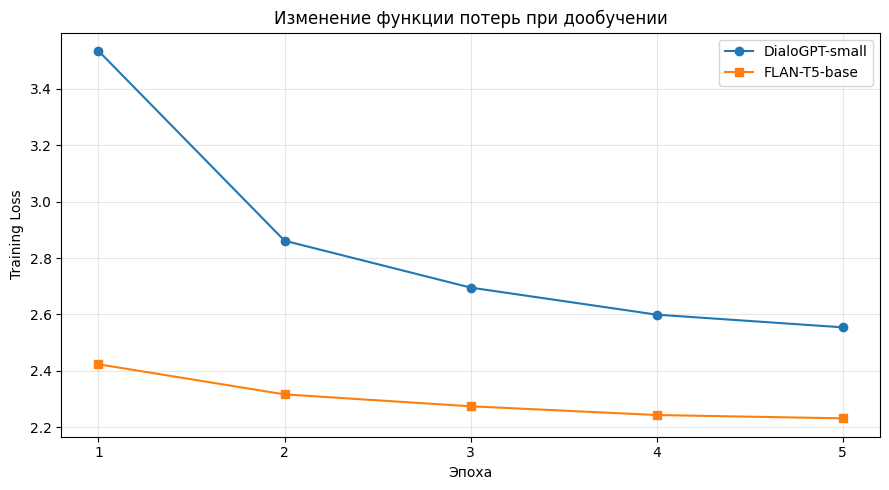

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    dialogpt_history["epoch"],
    dialogpt_history["train_loss"],
    marker="o",
    label="DialoGPT-small"
)

plt.plot(
    flan_history["epoch"],
    flan_history["train_loss"],
    marker="s",
    label="FLAN-T5-base"
)

plt.xlabel("Эпоха")
plt.ylabel("Training Loss")
plt.title("Изменение функции потерь при дообучении")

plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    "results/training_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


#### Вывод по пункту 5

В ходе дообучения обеих моделей на датасете DailyDialog наблюдалось постепенное снижение функции потерь на протяжении пяти эпох.

У модели **DialoGPT-small** значение loss уменьшилось с 3.5341 до 2.5542 (на 27,7%), а у **FLAN-T5-base** — с 2.4233 до 2.2316 (на 7,9%).

Наиболее заметное снижение ошибки у обеих моделей происходило на первых эпохах, после чего улучшение постепенно замедлялось. Это свидетельствует о том, что модели адаптируются к обучающим данным.

Таким образом, **дообучение обеих моделей прошло успешно**, а снижение training loss указывает на улучшение предсказания целевых ответов на обучающей выборке. Однако окончательно оценить влияние дообучения на качество генерации можно только после расчёта метрик BLEU и METEOR на валидационном подмножестве.

## 6. Проверка работы моделей после дообучения

На данном этапе проводится качественная оценка генерации ответов моделей DialoGPT-small и FLAN-T5-base после дообучения на обучающем подмножестве датасета DailyDialog.

Для проверки используются те же пять англоязычных запросов на повседневные темы, которые применялись в пункте 3 при тестировании исходных моделей в режиме zero-shot.

Обе модели загружаются из сохранённых локальных каталогов с дообученными весами.

Полученные ответы сравниваются с ответами исходных моделей. Анализ проводится с точки зрения смыслового соответствия запросу, связности и естественности диалоговых реплик.

Импорт библиотек и настройка окружения

In [75]:

import os
import gc
import torch
import pandas as pd

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM
)

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

MAX_INPUT_LENGTH = 128
MAX_TARGET_LENGTH = 64

DIALOGPT_SAVE_PATH = "models/dialogpt_finetuned"
FLAN_SAVE_PATH = "models/flan_t5_finetuned"

assert os.path.exists(
    os.path.join(DIALOGPT_SAVE_PATH, "config.json")
), "Сохранённая DialoGPT не найдена"

assert os.path.exists(
    os.path.join(FLAN_SAVE_PATH, "config.json")
), "Сохранённая FLAN-T5 не найдена"

print("Устройство:", device)
print("Обе обученные модели найдены.")


Устройство: cuda:0
Обе обученные модели найдены.


Подготовка тестовых запросов

In [76]:
test_contexts = [
    "User: Hello! How are you today?",
    "User: What are you doing this weekend?",
    "User: I am feeling a little tired today.",
    "User: Do you like watching movies?",
    "User: Can you help me with my homework?"
]

print("Количество тестовых запросов:", len(test_contexts))

for i, context in enumerate(test_contexts, start=1):
    print(f"{i}. {context}")


Количество тестовых запросов: 5
1. User: Hello! How are you today?
2. User: What are you doing this weekend?
3. User: I am feeling a little tired today.
4. User: Do you like watching movies?
5. User: Can you help me with my homework?


Загрузка ответов моделей до обучения

In [77]:
ZERO_SHOT_PATH = "results/zero_shot_examples.csv"

assert os.path.exists(ZERO_SHOT_PATH), (
    "Файл с исходными ответами не найден."
)

zero_shot_df = pd.read_csv(
    ZERO_SHOT_PATH,
    keep_default_na=False
)

required_columns = {
    "context",
    "dialogpt_before",
    "flan_before"
}

assert required_columns.issubset(zero_shot_df.columns)

assert zero_shot_df["context"].tolist() == test_contexts, (
    "Запросы отличаются от использованных в пункте 3"
)

print("Исходные ответы успешно загружены.")

display(zero_shot_df)


Исходные ответы успешно загружены.


,context,dialogpt_before,flan_before
0,User: Hello! How are you today?,Hi !,I'm fine.
1,User: What are you doing this weekend?,I'm going to the game tonight .,I'm going to the beach.
2,User: I am feeling a little tired today.,I'm feeling a little tired right now .,I'm not sure what to do.
3,User: Do you like watching movies?,I love movies .,I like to watch a lot of movies.
4,User: Can you help me with my homework?,I can help you with your homework,Sure. I'll help you with that.


Функция генерации ответа DialoGPT

In [79]:
def format_dialogpt_context(context):
    turns = []

    for line in context.split("\n"):
        if ": " in line:
            text = line.split(": ", 1)[1]
        else:
            text = line

        turns.append(text.strip())

    eos = dialogpt_tokenizer.eos_token

    return eos.join(turns) + eos


@torch.inference_mode()
def generate_dialogpt(context):
    prompt = format_dialogpt_context(context)

    inputs = dialogpt_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    ).to(device)

    outputs = dialogpt_model.generate(
        **inputs,
        max_new_tokens=MAX_TARGET_LENGTH,
        do_sample=False,
        pad_token_id=dialogpt_tokenizer.pad_token_id,
        eos_token_id=dialogpt_tokenizer.eos_token_id
    )

    # Удаляем входные токены
    input_length = inputs["input_ids"].shape[1]

    generated_ids = outputs[0, input_length:]

    response = dialogpt_tokenizer.decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )

    return response.strip()


Генерация ответов DialoGPT после обучения

In [80]:
dialogpt_examples_after = []

print("DialoGPT-small после обучения")
print("=" * 60)

for i, context in enumerate(test_contexts, start=1):
    response = generate_dialogpt(context)

    dialogpt_examples_after.append(response)

    print(f"\nПример {i}")
    print("Запрос:", context)
    print("Ответ:", response)
    print("-" * 60)

assert len(dialogpt_examples_after) == len(test_contexts)

print("\nГенерация DialoGPT завершена.")


DialoGPT-small после обучения

Пример 1
Запрос: User: Hello! How are you today?
Ответ: I ’ m fine . How about you ?
------------------------------------------------------------

Пример 2
Запрос: User: What are you doing this weekend?
Ответ: I'm going to go to the beach .
------------------------------------------------------------

Пример 3
Запрос: User: I am feeling a little tired today.
Ответ: I am sorry to hear that .
------------------------------------------------------------

Пример 4
Запрос: User: Do you like watching movies?
Ответ: Yes , I like watching movies .
------------------------------------------------------------

Пример 5
Запрос: User: Can you help me with my homework?
Ответ: Yes , I can .
------------------------------------------------------------

Генерация DialoGPT завершена.


In [81]:

del dialogpt_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("DialoGPT выгружена из GPU.")
print("Сгенерированные ответы сохранены.")


DialoGPT выгружена из GPU.
Сгенерированные ответы сохранены.


роверка дообученной FLAN-T5-base

In [82]:
flan_tokenizer = AutoTokenizer.from_pretrained(
    FLAN_SAVE_PATH
)

flan_model = AutoModelForSeq2SeqLM.from_pretrained(
    FLAN_SAVE_PATH,
    dtype=torch.float32
).to(device)

flan_model.eval()

print("Обученная FLAN-T5 загружена.")
print("Устройство:", next(flan_model.parameters()).device)


Loading weights: 100%|██████████| 282/282 [00:00<00:00, 1662.64it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Обученная FLAN-T5 загружена.
Устройство: cuda:0


Функция генерации FLAN-T5

In [83]:
def format_flan_context(context):
    instruction = (
        "Generate a natural and relevant next reply "
        "in the following conversation. "
        "Return only the reply."
    )

    return (
        f"{instruction}\n\n"
        f"{context}\n"
        "Assistant:"
    )


@torch.inference_mode()
def generate_flan(context):
    prompt = format_flan_context(context)

    inputs = flan_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    ).to(device)

    outputs = flan_model.generate(
        **inputs,
        max_new_tokens=MAX_TARGET_LENGTH,
        do_sample=False
    )

    response = flan_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )

    return response.strip()


Генерация ответов FLAN-T5 после обучения

In [84]:
flan_examples_after = []

print("FLAN-T5-base после обучения")
print("=" * 60)

for i, context in enumerate(test_contexts, start=1):
    response = generate_flan(context)

    flan_examples_after.append(response)

    print(f"\nПример {i}")
    print("Запрос:", context)
    print("Ответ:", response)
    print("-" * 60)

assert len(flan_examples_after) == len(test_contexts)

print("\nГенерация FLAN-T5 завершена.")


FLAN-T5-base после обучения

Пример 1
Запрос: User: Hello! How are you today?
Ответ: I'm fine.I'm feeling fine.I'm feeling very well.I'm feeling very well.I'm feeling very well.I'm feeling very well.I'm feeling very well.I'm feeling very well.I'm feeling very well.I'm feeling
------------------------------------------------------------

Пример 2
Запрос: User: What are you doing this weekend?
Ответ: I'm going to the beach.
------------------------------------------------------------

Пример 3
Запрос: User: I am feeling a little tired today.
Ответ: I'm sorry. I'm not feeling well.
------------------------------------------------------------

Пример 4
Запрос: User: Do you like watching movies?
Ответ: Yes, I do. I like to watch movies.
------------------------------------------------------------

Пример 5
Запрос: User: Can you help me with my homework?
Ответ: Yes, I'd like to.
------------------------------------------------------------

Генерация FLAN-T5 завершена.


Сравнение ответов до и после обучения

In [85]:
comparison_df = pd.DataFrame({
    "context": test_contexts,
    "dialogpt_before": zero_shot_df["dialogpt_before"].tolist(),
    "dialogpt_after": dialogpt_examples_after,
    "flan_before": zero_shot_df["flan_before"].tolist(),
    "flan_after": flan_examples_after
})

display(comparison_df)


,context,dialogpt_before,dialogpt_after,flan_before,flan_after
0,User: Hello! How are you today?,Hi !,I ’ m fine . How about you ?,I'm fine.,I'm fine.I'm feeling fine.I'm feeling very wel...
1,User: What are you doing this weekend?,I'm going to the game tonight .,I'm going to go to the beach .,I'm going to the beach.,I'm going to the beach.
2,User: I am feeling a little tired today.,I'm feeling a little tired right now .,I am sorry to hear that .,I'm not sure what to do.,I'm sorry. I'm not feeling well.
3,User: Do you like watching movies?,I love movies .,"Yes , I like watching movies .",I like to watch a lot of movies.,"Yes, I do. I like to watch movies."
4,User: Can you help me with my homework?,I can help you with your homework,"Yes , I can .",Sure. I'll help you with that.,"Yes, I'd like to."


### Вывод по пункту 6

После дообучения обеих моделей на датасете DailyDialog наблюдаются изменения в качестве генерируемых ответов.

Модель **DialoGPT-small** стала формировать более естественные и соответствующие контексту реплики. В частности, улучшились ответы на приветствие и сообщение об усталости пользователя.

Модель **FLAN-T5-base** также продемонстрировала улучшения в некоторых ответах, однако в отдельных случаях наблюдаются избыточная генерация, повторения и смысловые неточности.

Таким образом, дообучение положительно повлияло на качество отдельных ответов обеих моделей, причём на рассмотренных примерах DialoGPT-small показала более заметные улучшения. Для объективной оценки эффективности дообучения необходимо дополнительно сравнить значения BLEU и METEOR на валидационном подмножестве датасета.

## 7. Расчёт метрик BLEU и METEOR дообученных моделей

На данном этапе проводится количественная оценка качества генерации ответов моделей DialoGPT-small и FLAN-T5-base после дообучения на датасете DailyDialog.

Оценка выполняется на том же валидационном подмножестве, которое использовалось при тестировании исходных моделей в пункте 4.

Для каждого входного контекста дообученная модель генерирует ответ, который сравнивается с эталонной репликой из датасета.

Подготовка валидационных данных

In [ ]:
val_pairs = load_dataset(
    "json",
    data_files="data/val_pairs.jsonl",
    split="train"
)

validation_contexts = list(val_pairs["context"])
validation_references = list(val_pairs["response"])

assert len(validation_contexts) > 0
assert len(validation_contexts) == len(validation_references)

print("Количество валидационных примеров:",
      len(validation_contexts))

print("\nПример контекста:")
print(validation_contexts[0])

print("\nЭталонный ответ:")
print(validation_references[0])


Generating train split: 798 examples [00:00, 395445.96 examples/s]

Количество валидационных примеров: 798

Пример контекста:
User: my mp3 player is broken , so I want to change it for an mp4 player . Can you offer any advice about which brand and model to buy ?

Эталонный ответ:
an mp4 player ? why don't you buy a new cell phone ? You can find an mp4 player inside any of the latest cell phones .


Загрузка BLEU и METEOR

In [90]:
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

bleu_metric = evaluate.load("bleu")
meteor_metric = evaluate.load("meteor")

print("BLEU и METEOR загружены.")


/home/lonaogoda/spailb/.venvconvlb/lib/python3.10/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/lonaogoda/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


BLEU и METEOR загружены.


[nltk_data] Downloading package wordnet to
[nltk_data]     /home/lonaogoda/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/lonaogoda/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /home/lonaogoda/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Функция расчёта метрик

In [92]:
def calculate_metrics(predictions, references):
    predictions = list(predictions)
    references = list(references)

    if not predictions:
        raise ValueError("Список предсказаний пуст.")

    if len(predictions) != len(references):
        raise ValueError(
            f"Предсказаний: {len(predictions)}, "
            f"эталонов: {len(references)}"
        )

    if any(not isinstance(x, str) for x in predictions):
        raise TypeError("Предсказания должны быть строками.")

    if any(not isinstance(x, str) for x in references):
        raise TypeError("Эталонные ответы должны быть строками.")

    if any(not x.strip() for x in references):
        raise ValueError("Обнаружены пустые эталонные ответы.")

    bleu = bleu_metric.compute(
        predictions=predictions,
        references=[[ref] for ref in references]
    )["bleu"]

    meteor = meteor_metric.compute(
        predictions=predictions,
        references=references
    )["meteor"]

    return {
        "BLEU": round(bleu, 4),
        "METEOR": round(meteor, 4)
    }


Оценка дообученной DialoGPT-small

Загрузка дообученной DialoGPT-small

In [93]:
# Освобождаем GPU
if "flan_model" in globals():
    del flan_model

if "dialogpt_model" in globals():
    del dialogpt_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Загружаем дообученную DialoGPT
dialogpt_tokenizer = AutoTokenizer.from_pretrained(
    DIALOGPT_SAVE_PATH
)

dialogpt_tokenizer.pad_token = (
    dialogpt_tokenizer.eos_token
)

dialogpt_tokenizer.padding_side = "left"

dialogpt_model = AutoModelForCausalLM.from_pretrained(
    DIALOGPT_SAVE_PATH,
    dtype=torch.float32
).to(device)

dialogpt_model.config.pad_token_id = (
    dialogpt_tokenizer.pad_token_id
)

dialogpt_model.eval()

print("Модель:", DIALOGPT_SAVE_PATH)
print("Устройство:", next(dialogpt_model.parameters()).device)
print("Модель готова к оценке.")


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 1755.81it/s]


Модель: models/dialogpt_finetuned
Устройство: cuda:0
Модель готова к оценке.


Функция подготовки контекста DialoGPT

In [94]:
def format_dialogpt_context(context):
    turns = []

    for line in context.split("\n"):
        if ": " in line:
            text = line.split(": ", 1)[1]
        else:
            text = line

        turns.append(text.strip())

    eos = dialogpt_tokenizer.eos_token

    return eos.join(turns) + eos


print(format_dialogpt_context(validation_contexts[0]))


my mp3 player is broken , so I want to change it for an mp4 player . Can you offer any advice about which brand and model to buy ?<|endoftext|>


Функция пакетной генерации DialoGPT

In [95]:
@torch.inference_mode()
def generate_dialogpt_batch(contexts):
    prompts = [
        format_dialogpt_context(context)
        for context in contexts
    ]

    inputs = dialogpt_tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    ).to(device)

    outputs = dialogpt_model.generate(
        **inputs,
        max_new_tokens=MAX_TARGET_LENGTH,
        do_sample=False,
        pad_token_id=dialogpt_tokenizer.pad_token_id,
        eos_token_id=dialogpt_tokenizer.eos_token_id
    )

    input_length = inputs["input_ids"].shape[1]

    generated_ids = outputs[:, input_length:]

    responses = dialogpt_tokenizer.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )

    return [response.strip() for response in responses]


Генерация ответов DialoGPT на всём валидационном сабсете

In [96]:
dialogpt_predictions_after = []

for i in tqdm(
    range(0, len(validation_contexts), BATCH_SIZE_EVAL),
    desc="DialoGPT fine-tuned"
):
    batch = validation_contexts[
        i:i + BATCH_SIZE_EVAL
    ]

    responses = generate_dialogpt_batch(batch)

    dialogpt_predictions_after.extend(responses)

assert len(dialogpt_predictions_after) == len(
    validation_references
)

print("Сгенерировано ответов:",
      len(dialogpt_predictions_after))

print(
    "Пустых ответов:",
    sum(not x.strip() for x in dialogpt_predictions_after)
)


DialoGPT fine-tuned: 100%|██████████| 50/50 [00:11<00:00,  4.28it/s]

Сгенерировано ответов: 798
Пустых ответов: 2


Расчёт BLEU и METEOR DialoGPT после обучения

In [97]:
dialogpt_metrics_after = calculate_metrics(
    dialogpt_predictions_after,
    validation_references
)

print("DialoGPT-small после дообучения")
print("=" * 45)

print("BLEU:", dialogpt_metrics_after["BLEU"])
print("METEOR:", dialogpt_metrics_after["METEOR"])


DialoGPT-small после дообучения
BLEU: 0.0124
METEOR: 0.1271


In [98]:
dialogpt_results_after_df = pd.DataFrame({
    "context": validation_contexts,
    "reference": validation_references,
    "prediction": dialogpt_predictions_after
})

dialogpt_results_after_df.to_csv(
    "results/dialogpt_predictions_after.csv",
    index=False,
    encoding="utf-8"
)

with open(
    "results/dialogpt_metrics_after.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        dialogpt_metrics_after,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Результаты DialoGPT сохранены.")


Результаты DialoGPT сохранены.


Оценка дообученной FLAN-T5-base

In [99]:
if "dialogpt_model" in globals():
    del dialogpt_model

if "flan_model" in globals():
    del flan_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

flan_tokenizer = AutoTokenizer.from_pretrained(
    FLAN_SAVE_PATH
)

flan_model = AutoModelForSeq2SeqLM.from_pretrained(
    FLAN_SAVE_PATH,
    dtype=torch.float32
).to(device)

flan_model.config.use_cache = True
flan_model.eval()

print("Модель:", FLAN_SAVE_PATH)
print("Устройство:", next(flan_model.parameters()).device)
print("Модель готова к оценке.")


Loading weights: 100%|██████████| 282/282 [00:00<00:00, 1670.18it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Модель: models/flan_t5_finetuned
Устройство: cuda:0
Модель готова к оценке.


Подготовка контекста FLAN-T5

In [100]:
def format_flan_context(context):
    instruction = (
        "Generate a natural and relevant next reply "
        "in the following conversation. "
        "Return only the reply."
    )

    return (
        f"{instruction}\n\n"
        f"{context}\n"
        "Assistant:"
    )


print(format_flan_context(validation_contexts[0]))


Generate a natural and relevant next reply in the following conversation. Return only the reply.

User: my mp3 player is broken , so I want to change it for an mp4 player . Can you offer any advice about which brand and model to buy ?
Assistant:


Функция пакетной генерации FLAN-T5

In [101]:
@torch.inference_mode()
def generate_flan_batch(contexts):
    prompts = [
        format_flan_context(context)
        for context in contexts
    ]

    inputs = flan_tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    ).to(device)

    outputs = flan_model.generate(
        **inputs,
        max_new_tokens=MAX_TARGET_LENGTH,
        do_sample=False
    )

    responses = flan_tokenizer.batch_decode(
        outputs,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )

    return [response.strip() for response in responses]


Генерация ответов FLAN-T5 на валидационном сабсете

In [102]:
flan_predictions_after = []

for i in tqdm(
    range(0, len(validation_contexts), BATCH_SIZE_EVAL),
    desc="FLAN-T5 fine-tuned"
):
    batch = validation_contexts[
        i:i + BATCH_SIZE_EVAL
    ]

    responses = generate_flan_batch(batch)

    flan_predictions_after.extend(responses)

assert len(flan_predictions_after) == len(
    validation_references
)

print("Сгенерировано ответов:",
      len(flan_predictions_after))

print(
    "Пустых ответов:",
    sum(not x.strip() for x in flan_predictions_after)
)


FLAN-T5 fine-tuned: 100%|██████████| 50/50 [00:28<00:00,  1.78it/s]

Сгенерировано ответов: 798
Пустых ответов: 0


Расчёт BLEU и METEOR FLAN-T5 после обучения

In [103]:
flan_metrics_after = calculate_metrics(
    flan_predictions_after,
    validation_references
)

print("FLAN-T5-base после дообучения")
print("=" * 45)

print("BLEU:", flan_metrics_after["BLEU"])
print("METEOR:", flan_metrics_after["METEOR"])


FLAN-T5-base после дообучения
BLEU: 0.0139
METEOR: 0.1424


In [104]:

flan_results_after_df = pd.DataFrame({
    "context": validation_contexts,
    "reference": validation_references,
    "prediction": flan_predictions_after
})

flan_results_after_df.to_csv(
    "results/flan_predictions_after.csv",
    index=False,
    encoding="utf-8"
)

with open(
    "results/flan_metrics_after.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        flan_metrics_after,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Результаты FLAN-T5 сохранены.")


Результаты FLAN-T5 сохранены.


Итоговая таблица и проверка результатов

In [105]:
metrics_after_df = pd.DataFrame([
    {
        "Модель": "DialoGPT-small",
        "Архитектура": "Decoder-only",
        "BLEU": dialogpt_metrics_after["BLEU"],
        "METEOR": dialogpt_metrics_after["METEOR"]
    },
    {
        "Модель": "FLAN-T5-base",
        "Архитектура": "Encoder-decoder",
        "BLEU": flan_metrics_after["BLEU"],
        "METEOR": flan_metrics_after["METEOR"]
    }
])

display(metrics_after_df)


,Модель,Архитектура,BLEU,METEOR
0,DialoGPT-small,Decoder-only,0.0124,0.1271
1,FLAN-T5-base,Encoder-decoder,0.0139,0.1424


In [106]:
metrics_after_df.to_csv(
    "results/metrics_after.csv",
    index=False,
    encoding="utf-8"
)

print("Метрики сохранены:")
print("results/metrics_after.csv")


Метрики сохранены:
results/metrics_after.csv


### Вывод

В ходе оценки дообученных моделей на валидационном подмножестве датасета DailyDialog были получены значения метрик BLEU и METEOR.

Модель **DialoGPT-small** показала BLEU = 0.0124 и METEOR = 0.1271, а **FLAN-T5-base** — BLEU = 0.0139 и METEOR = 0.1424.

По сравнению с исходными моделями значения обеих метрик увеличились, что свидетельствует о положительном влиянии дообучения на качество генерации ответов.

При этом **FLAN-T5-base продемонстрировала более высокие показатели BLEU и METEOR**, сохранив преимущество над DialoGPT-small.

Таким образом, дообучение обеих моделей в течение пяти эпох позволило повысить соответствие генерируемых ответов эталонным репликам. Полученные результаты подтверждают эффективность адаптации моделей к датасету DailyDialog.

## Сохранение метрик

In [ ]:
before = pd.read_csv("results/metrics_before.csv")
after = pd.read_csv("results/metrics_after.csv")

comparison = before.merge(
    after,
    on=["Модель", "Архитектура"],
    suffixes=("_до", "_после")
)

for metric in ["BLEU", "METEOR"]:
    comparison[f"{metric}_изменение_%"] = (
        (comparison[f"{metric}_после"] -
         comparison[f"{metric}_до"])
        / comparison[f"{metric}_до"]
        * 100
    ).round(2)

display(comparison)

comparison.to_csv(
    "results/final_comparison.csv",
    index=False
)


,Модель,Архитектура,BLEU_до,METEOR_до,BLEU_после,METEOR_после,BLEU_изменение_%,METEOR_изменение_%
0,DialoGPT-small,Decoder-only,0.0056,0.1049,0.0124,0.1271,121.43,21.16
1,FLAN-T5-base,Encoder-decoder,0.0104,0.1213,0.0139,0.1424,33.65,17.39


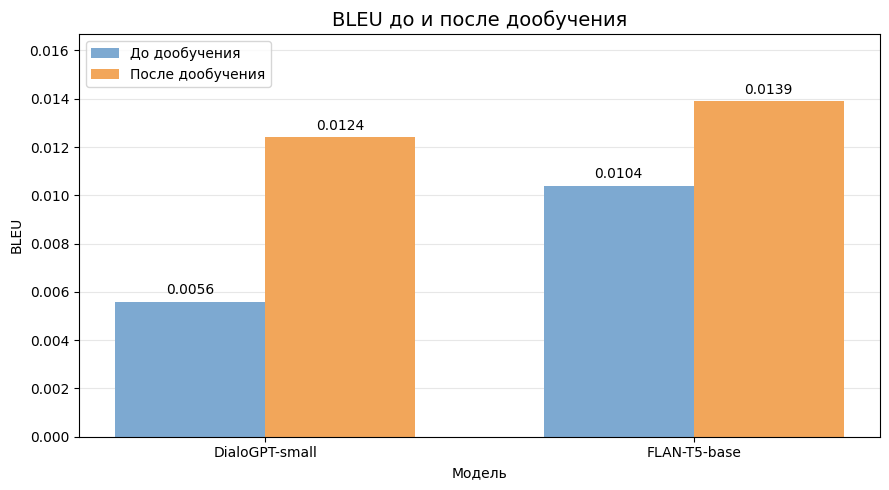

График сохранён: results/bleu_comparison.png


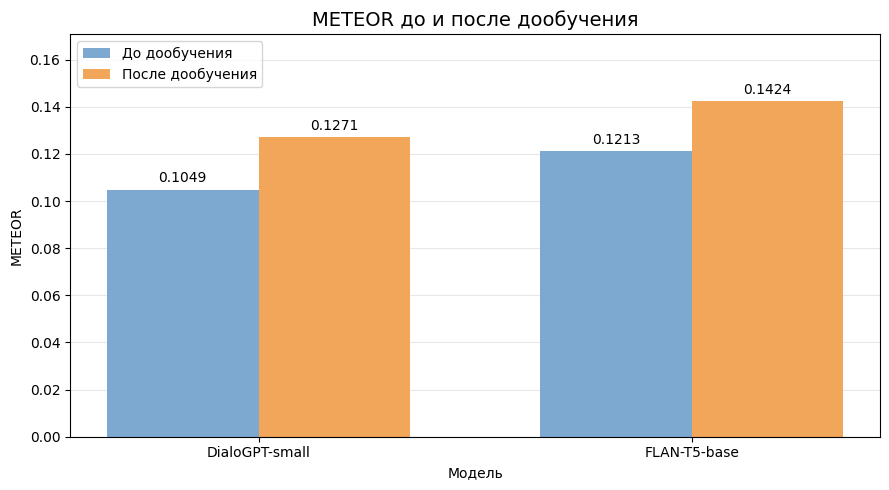

График сохранён: results/meteor_comparison.png


In [108]:
# Загружаем результаты пунктов 4 и 7
before = pd.read_csv("results/metrics_before.csv")
after = pd.read_csv("results/metrics_after.csv")

# Объединяем таблицы
comparison = before.merge(
    after,
    on=["Модель", "Архитектура"],
    suffixes=("_до", "_после")
)

os.makedirs("results", exist_ok=True)

models = comparison["Модель"].tolist()
x = np.arange(len(models))
width = 0.35

# Строим отдельный график для каждой метрики
for metric in ["BLEU", "METEOR"]:
    before_values = comparison[f"{metric}_до"]
    after_values = comparison[f"{metric}_после"]

    fig, ax = plt.subplots(figsize=(9, 5))

    bars_before = ax.bar(
        x - width / 2,
        before_values,
        width,
        label="До дообучения",
        color="#7DA9D1"
    )

    bars_after = ax.bar(
        x + width / 2,
        after_values,
        width,
        label="После дообучения",
        color="#F2A65A"
    )

    # Значения над столбцами
    ax.bar_label(
        bars_before,
        fmt="%.4f",
        padding=3
    )

    ax.bar_label(
        bars_after,
        fmt="%.4f",
        padding=3
    )

    ax.set_title(
        f"{metric} до и после дообучения",
        fontsize=14
    )

    ax.set_xlabel("Модель")
    ax.set_ylabel(metric)

    ax.set_xticks(x)
    ax.set_xticklabels(models)

    ax.set_ylim(
        0,
        max(before_values.max(), after_values.max()) * 1.2
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()

    # Сохранение графика
    filename = f"results/{metric.lower()}_comparison.png"
    plt.savefig(filename, dpi=150, bbox_inches="tight")

    plt.show()

    print(f"График сохранён: {filename}")


In [111]:

import os
import gc
import json
import math
import random

import numpy as np
import pandas as pd
import torch
import evaluate

from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from datasets import load_dataset

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    get_linear_schedule_with_warmup
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda", "Для этого эксперимента нужен CUDA GPU"

DECODER_MODEL = "microsoft/DialoGPT-small"
ENCODER_DECODER_MODEL = "google/flan-t5-base"

EPOCHS_V2 = 5
LEARNING_RATE_V2 = 2e-5
BATCH_SIZE_TRAIN_V2 = 4
GRAD_ACCUM_V2 = 4
BATCH_SIZE_EVAL_V2 = 16

MAX_INPUT_LENGTH = 128
MAX_TARGET_LENGTH = 64

DIALOGPT_V2_PATH = "models/dialogpt_finetuned_v2"
FLAN_V2_PATH = "models/flan_t5_finetuned_v2"

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

# Восстанавливаем данные, если ядро Jupyter перезапускалось
if "train_pairs_v2" not in globals():
    train_pairs_v2 = load_dataset(
        "json",
        data_files="data/train_pairs_v2.jsonl",
        split="train"
    )

# Валидация из первого эксперимента
validation_df = pd.read_csv(
    "results/predictions_before.csv",
    keep_default_na=False
)

validation_contexts = validation_df["context"].tolist()
validation_references = validation_df["reference"].tolist()

assert len(train_pairs_v2) > 0
assert len(validation_contexts) > 0
assert len(validation_contexts) == len(validation_references)

print("GPU:", torch.cuda.get_device_name(0))
print("Train pairs v2:", len(train_pairs_v2))
print("Validation pairs:", len(validation_contexts))
print("Epochs:", EPOCHS_V2)
print("Effective batch:", BATCH_SIZE_TRAIN_V2 * GRAD_ACCUM_V2)


GPU: NVIDIA GeForce RTX 3060
Train pairs v2: 54863
Validation pairs: 798
Epochs: 5
Effective batch: 16


In [112]:

def train_model_v2(model, dataloader, model_name):
    model = model.float().to(device)
    model.config.use_cache = False

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE_V2,
        weight_decay=0.01
    )

    steps_per_epoch = math.ceil(
        len(dataloader) / GRAD_ACCUM_V2
    )

    total_steps = steps_per_epoch * EPOCHS_V2

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=max(1, int(total_steps * 0.05)),
        num_training_steps=total_steps
    )

    history = []

    for epoch in range(EPOCHS_V2):
        model.train()
        optimizer.zero_grad(set_to_none=True)

        total_loss = 0.0

        progress = tqdm(
            enumerate(dataloader),
            total=len(dataloader),
            desc=f"{model_name} | Epoch {epoch + 1}/{EPOCHS_V2}"
        )

        for step, batch in progress:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(**batch)
            loss = outputs.loss

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    f"Неконечный loss: {model_name}, "
                    f"epoch={epoch + 1}, batch={step + 1}"
                )

            total_loss += loss.detach().item()

            group_start = (
                step // GRAD_ACCUM_V2
            ) * GRAD_ACCUM_V2

            group_size = min(
                GRAD_ACCUM_V2,
                len(dataloader) - group_start
            )

            (loss / group_size).backward()

            should_step = (
                (step + 1) % GRAD_ACCUM_V2 == 0
                or step + 1 == len(dataloader)
            )

            if should_step:
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0,
                    error_if_nonfinite=True
                )

                optimizer.step()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)

            progress.set_postfix(
                loss=f"{loss.item():.4f}"
            )

        avg_loss = total_loss / len(dataloader)

        history.append({
            "epoch": epoch + 1,
            "train_loss": avg_loss
        })

        print(
            f"{model_name}: эпоха {epoch + 1}, "
            f"train_loss = {avg_loss:.4f}"
        )

    model.config.use_cache = True
    return pd.DataFrame(history)


In [113]:

# Выгружаем старые модели, если они остались в памяти
for name in ["dialogpt_model", "flan_model"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

dialogpt_tokenizer = AutoTokenizer.from_pretrained(
    DECODER_MODEL
)

dialogpt_tokenizer.pad_token = dialogpt_tokenizer.eos_token
dialogpt_tokenizer.padding_side = "right"
dialogpt_tokenizer.truncation_side = "left"

def tokenize_dialogpt_v2(example):
    # Формат подготовки, используемый при обучении
    lines = example["context"].split("\n")
    turns = [
        line.split(": ", 1)[1] if ": " in line else line
        for line in lines
    ]

    eos = dialogpt_tokenizer.eos_token
    prompt = eos.join(turns) + eos

    prompt_ids = dialogpt_tokenizer(
        prompt,
        add_special_tokens=False
    )["input_ids"][-MAX_INPUT_LENGTH:]

    answer_ids = dialogpt_tokenizer(
        example["response"] + eos,
        add_special_tokens=False
    )["input_ids"][:MAX_TARGET_LENGTH]

    return {
        "input_ids": prompt_ids + answer_ids,
        "labels": [-100] * len(prompt_ids) + answer_ids
    }


dialogpt_dataset_v2 = train_pairs_v2.map(
    tokenize_dialogpt_v2,
    remove_columns=train_pairs_v2.column_names,
    desc="Токенизация DialoGPT v2"
)

def dialogpt_collator_v2(features):
    max_len = max(len(x["input_ids"]) for x in features)
    pad_id = dialogpt_tokenizer.pad_token_id

    return {
        "input_ids": torch.tensor([
            x["input_ids"] + [pad_id] * (max_len - len(x["input_ids"]))
            for x in features
        ], dtype=torch.long),

        "attention_mask": torch.tensor([
            [1] * len(x["input_ids"])
            + [0] * (max_len - len(x["input_ids"]))
            for x in features
        ], dtype=torch.long),

        "labels": torch.tensor([
            x["labels"] + [-100] * (max_len - len(x["labels"]))
            for x in features
        ], dtype=torch.long)
    }


dialogpt_loader_v2 = DataLoader(
    dialogpt_dataset_v2,
    batch_size=BATCH_SIZE_TRAIN_V2,
    shuffle=True,
    collate_fn=dialogpt_collator_v2,
    pin_memory=True
)

print("Обучающих пар:", len(dialogpt_dataset_v2))
print("Батчей:", len(dialogpt_loader_v2))


Токенизация DialoGPT v2: 100%|██████████| 54863/54863 [00:11<00:00, 4718.19 examples/s] 

Обучающих пар: 54863
Батчей: 13716


In [114]:

dialogpt_model = AutoModelForCausalLM.from_pretrained(
    DECODER_MODEL,
    dtype=torch.float32
).to(device)

dialogpt_model.config.pad_token_id = (
    dialogpt_tokenizer.pad_token_id
)

print("Начинаем обучение DialoGPT v2")

dialogpt_history_v2 = train_model_v2(
    model=dialogpt_model,
    dataloader=dialogpt_loader_v2,
    model_name="DialoGPT v2"
)

display(dialogpt_history_v2)


Loading weights: 100%|██████████| 149/149 [00:00<00:00, 711.61it/s]


Начинаем обучение DialoGPT v2


DialoGPT v2 | Epoch 1/5: 100%|██████████| 13716/13716 [19:33<00:00, 11.69it/s, loss=2.7161]


DialoGPT v2: эпоха 1, train_loss = 3.0504


DialoGPT v2 | Epoch 2/5: 100%|██████████| 13716/13716 [19:35<00:00, 11.67it/s, loss=2.1348]


DialoGPT v2: эпоха 2, train_loss = 2.5934


... (3 outputs left out)

DialoGPT v2: эпоха 4, train_loss = 2.4044


DialoGPT v2 | Epoch 5/5: 100%|██████████| 13716/13716 [19:40<00:00, 11.62it/s, loss=2.3508]

DialoGPT v2: эпоха 5, train_loss = 2.3596


,epoch,train_loss
0,1,3.050403
1,2,2.593443
2,3,2.475107
3,4,2.404412
4,5,2.359559


In [115]:

dialogpt_model.save_pretrained(DIALOGPT_V2_PATH)
dialogpt_tokenizer.save_pretrained(DIALOGPT_V2_PATH)

dialogpt_history_v2.to_csv(
    "results/dialogpt_history_v2.csv",
    index=False
)

print("DialoGPT v2 сохранена:", DIALOGPT_V2_PATH)
display(dialogpt_history_v2)

del dialogpt_model
del dialogpt_loader_v2
del dialogpt_dataset_v2

gc.collect()
torch.cuda.empty_cache()


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.27it/s]

DialoGPT v2 сохранена: models/dialogpt_finetuned_v2


,epoch,train_loss
0,1,3.050403
1,2,2.593443
2,3,2.475107
3,4,2.404412
4,5,2.359559


In [116]:

flan_tokenizer = AutoTokenizer.from_pretrained(
    ENCODER_DECODER_MODEL
)

def format_flan_context_v2(context):
    instruction = (
        "Generate a natural and relevant next reply "
        "in the following conversation. "
        "Return only the reply."
    )

    return (
        f"{instruction}\n\n"
        f"{context}\n"
        "Assistant:"
    )


def tokenize_flan_v2(example):
    prompt = format_flan_context_v2(
        example["context"]
    )

    inputs = flan_tokenizer(
        prompt,
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    )

    targets = flan_tokenizer(
        text_target=example["response"],
        truncation=True,
        max_length=MAX_TARGET_LENGTH
    )

    inputs["labels"] = targets["input_ids"]

    return inputs


flan_dataset_v2 = train_pairs_v2.map(
    tokenize_flan_v2,
    remove_columns=train_pairs_v2.column_names,
    desc="Токенизация FLAN-T5 v2"
)

print("Обучающих пар:", len(flan_dataset_v2))


Токенизация FLAN-T5 v2: 100%|██████████| 54863/54863 [00:15<00:00, 3593.98 examples/s] 

Обучающих пар: 54863


In [117]:

flan_model = AutoModelForSeq2SeqLM.from_pretrained(
    ENCODER_DECODER_MODEL,
    dtype=torch.float32
).to(device)

flan_model.config.use_cache = False
flan_model.gradient_checkpointing_enable()

flan_collator_v2 = DataCollatorForSeq2Seq(
    tokenizer=flan_tokenizer,
    model=flan_model,
    padding=True,
    label_pad_token_id=-100,
    return_tensors="pt"
)

flan_loader_v2 = DataLoader(
    flan_dataset_v2,
    batch_size=BATCH_SIZE_TRAIN_V2,
    shuffle=True,
    collate_fn=flan_collator_v2,
    pin_memory=True
)

print("Батчей:", len(flan_loader_v2))
print("FLAN-T5 готова к обучению.")


Loading weights: 100%|██████████| 282/282 [00:00<00:00, 296.07it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Батчей: 13716
FLAN-T5 готова к обучению.


In [118]:

print("Начинаем обучение FLAN-T5 v2")

flan_history_v2 = train_model_v2(
    model=flan_model,
    dataloader=flan_loader_v2,
    model_name="FLAN-T5 v2"
)

display(flan_history_v2)


Начинаем обучение FLAN-T5 v2


FLAN-T5 v2 | Epoch 1/5:   0%|          | 0/13716 [00:00<?, ?it/s][transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
FLAN-T5 v2 | Epoch 1/5: 100%|██████████| 13716/13716 [50:41<00:00,  4.51it/s, loss=2.3553] 


FLAN-T5 v2: эпоха 1, train_loss = 2.3513


FLAN-T5 v2 | Epoch 2/5: 100%|██████████| 13716/13716 [50:29<00:00,  4.53it/s, loss=2.2459] 


FLAN-T5 v2: эпоха 2, train_loss = 2.2405


FLAN-T5 v2 | Epoch 3/5: 100%|██████████| 13716/13716 [50:27<00:00,  4.53it/s, loss=2.0131] 


... (2 outputs left out)

FLAN-T5 v2: эпоха 4, train_loss = 2.1628


FLAN-T5 v2 | Epoch 5/5: 100%|██████████| 13716/13716 [50:23<00:00,  4.54it/s, loss=1.3691] 

FLAN-T5 v2: эпоха 5, train_loss = 2.1462


,epoch,train_loss
0,1,2.351260
1,2,2.240477
2,3,2.191752
3,4,2.162762
4,5,2.146193


In [119]:

flan_model.gradient_checkpointing_disable()
flan_model.config.use_cache = True

flan_model.save_pretrained(FLAN_V2_PATH)
flan_tokenizer.save_pretrained(FLAN_V2_PATH)

flan_history_v2.to_csv(
    "results/flan_history_v2.csv",
    index=False
)

print("FLAN-T5 v2 сохранена:", FLAN_V2_PATH)
display(flan_history_v2)

del flan_model
del flan_loader_v2
del flan_dataset_v2

gc.collect()
torch.cuda.empty_cache()


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.86s/it]

FLAN-T5 v2 сохранена: models/flan_t5_finetuned_v2


,epoch,train_loss
0,1,2.351260
1,2,2.240477
2,3,2.191752
3,4,2.162762
4,5,2.146193
